# Attention Mechanism

## What is the drawback of the RNN Encoder-Decoder approach for machine translation?

основной дроубэк в том, что мы сжимаем наш текст, за счет чего теряем информацию, отсюда же следует проблема затухания градинетов и забывчивости самой нейронки, и в добавок нет понимания какое слово связано с каким

## What is positional encoding and why is it needed?




здесь решается другая проблема, даже когда мы используем self-attention (n^2), и рассчитываем взаимодействия между всеми словами у нас теряется информаиция о местоположении слов в тексте, эта проблема решается positinal энкодингом. есть два способа: применение синуса и косинуса и трейнбл параметры (через nn.embedding). первый вариант популярнее, менее затратный по памяти и скорости, а второй наоборот, и если и применяется в более простых моделях, где создают просто отдельный тензор чтобы просчитывать позиции. ключевой момент в том что при скалярном произведении для pos и pos+k у нас сокращаются pos и остается только k, за счет чего мы сможем через синус или косинус заметно проще считать то, насколько слова близко расположены

$$
\begin{aligned}
PE_{(pos, 2i)} &= \sin\left( \frac{pos}{10000^{2i / d_{\text{model}}}} \right) \\
PE_{(pos, 2i+1)} &= \cos\left( \frac{pos}{10000^{2i / d_{\text{model}}}} \right)
\end{aligned}
$$

# Data preparation

In [17]:
import pandas as pd
import numpy as np
import string
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [18]:
df = pd.read_csv("../datasets/baby_names.csv", sep=';')
df2 = pd.read_csv("../datasets/babynames-clean.csv")

df.columns = ['name', 'translated', 'male']
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6780 entries, 0 to 6779
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        6780 non-null   object
 1   translated  6780 non-null   object
 2   male        6780 non-null   object
dtypes: object(3)
memory usage: 159.0+ KB


In [19]:
len_ru = df['translated'].str.len().max()
len_ru

np.int64(13)

In [20]:
damn = list("Съешь ещё этих мягких французских булок да выпей же чаю".lower().replace(" ", ""))
damn.append('<PAD>')
damn.append('<SOS>')
damn.append('<EOS>')
ru = np.unique(damn).tolist()

ru_char2id = {char: idx for idx, char in enumerate(ru)}
ru_id2char = {idx: char for char, idx in ru_char2id.items()}

In [21]:
eng = list(string.ascii_lowercase)
eng.append('<PAD>')
eng.append('<SOS>')
eng.append('<EOS>')

eng_char2id = {char: idx for idx, char in enumerate(eng)}
eng_id2char = {idx: char for char, idx in eng_char2id.items()}
len(eng_char2id)

29

In [22]:
max_len = 13

def pad_name(name):
    seq = ['<SOS>']
    seq.extend(name.lower())
    seq.append('<EOS>')

    cur_len = len(seq)
    while cur_len < max_len:
        seq.append('<PAD>')
        cur_len += 1
    
    return seq

df["padded"] = df['name'].apply(pad_name)


max_len = 15

def pad_name(name):
    seq = ['<SOS>']
    seq.extend(name.lower())
    seq.append('<EOS>')

    cur_len = len(seq)
    while cur_len < max_len:
        seq.append('<PAD>')
        cur_len += 1
    
    return seq

df["ru_padded"] = df['translated'].apply(pad_name)

In [23]:
def encode_tokens(tokens, char2id):
    return [char2id[token] for token in tokens]

df['gender'] = (df['male'] == "boy").astype(int)

df['name_encoded'] = df['padded'].apply(lambda tokens: encode_tokens(tokens, eng_char2id))
df['ru_name_encoded'] = df['ru_padded'].apply(lambda tokens: encode_tokens(tokens, ru_char2id))
df['name_encoded']

0       [27, 9, 14, 7, 13, 28, 26, 26, 26, 26, 26, 26,...
1       [27, 22, 8, 11, 11, 8, 0, 12, 28, 26, 26, 26, 26]
2       [27, 9, 0, 12, 4, 18, 28, 26, 26, 26, 26, 26, 26]
3        [27, 2, 7, 0, 17, 11, 4, 18, 28, 26, 26, 26, 26]
4        [27, 6, 4, 14, 17, 6, 4, 28, 26, 26, 26, 26, 26]
                              ...                        
6775    [27, 11, 0, 24, 11, 0, 7, 28, 26, 26, 26, 26, 26]
6776       [27, 2, 0, 17, 11, 4, 8, 6, 7, 28, 26, 26, 26]
6777    [27, 10, 4, 13, 11, 4, 24, 28, 26, 26, 26, 26,...
6778    [27, 18, 11, 14, 0, 13, 4, 28, 26, 26, 26, 26,...
6779     [27, 4, 11, 8, 0, 13, 13, 0, 28, 26, 26, 26, 26]
Name: name_encoded, Length: 6780, dtype: object

In [24]:
X = df['name_encoded']
y = df['gender']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_valid, X_test, y_valid, y_test = train_test_split(X_valid, y_valid, test_size=0.5, random_state=42, stratify=y_valid)
print(X_train.shape)
print(X_valid.shape)

(5424,)
(678,)


# RNN Encoder

In [25]:
X_train_t = torch.tensor(X_train.tolist(), dtype=torch.long)
y_train_t = torch.tensor(y_train.values, dtype=torch.int64).view(-1, 1)
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

X_valid_t = torch.tensor(X_valid.tolist(), dtype=torch.long)
y_valid_t = torch.tensor(y_valid.values, dtype=torch.int64).view(-1, 1)
valid_dataset = TensorDataset(X_valid_t, y_valid_t)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=True)

X_test_t = torch.tensor(X_test.tolist(), dtype=torch.long)
y_test_t = torch.tensor(y_test.values, dtype=torch.int64).view(-1, 1)
test_dataset = TensorDataset(X_test_t, y_test_t)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

In [73]:
class RNNEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128):
        super().__init__()

        self.vocab_size = vocab_size
        self.embedding_size = embedding_size
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=eng_char2id['<PAD>'])
        self.gru = nn.GRU(embedding_size, hidden_size, num_layers=1, batch_first=True)
        self.outputs_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        embedded = self.embedding(x)
        if hidden is None:
            outputs, hidden = self.gru(embedded)
        else:
            outputs, hidden = self.gru(embedded, hidden)
        logits = self.outputs_layer(outputs)
        return logits, outputs, hidden  
    
    def generate_name(self, temperature=1.0, max_len=13):
        self.eval()

        start_id = eng_char2id['<SOS>']
        end_id = eng_char2id['<EOS>']

        curr_id = torch.tensor([[start_id]], dtype=torch.long)
        generate_ids = [start_id]
        hidden = None

        for _ in range(max_len):
            outputs = self(curr_id, hidden)
            hidden = outputs[2]
            logits = outputs[0][:, -1, :]
            logits = logits / temperature

            probs = torch.softmax(logits, dim=-1)
            next_letter = torch.multinomial(probs, num_samples=1).item()

            if next_letter == end_id:
                break

            generate_ids.append(next_letter)
            curr_id = torch.tensor([[next_letter]], dtype=torch.long)

        return ''.join(eng_id2char[letter] for letter in generate_ids[1:])

In [74]:
def train_model(model, train_loader, valid_loader, epochs=50, lr=3e-4, stop=5):
    optimizer = torch.optim.Adam(model.parameters(), lr)
    criterion = nn.CrossEntropyLoss(ignore_index=eng_char2id['<PAD>'])

    best_valid_loss = float('inf')
    best_state = None

    train_losses = []
    valid_losses = []

    epochs_without_upgrade = 0
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for X_train, y_train in train_loader:
            outputs = model(X_train)
            logits = outputs[0][:, :-1, :].reshape(-1, 29)
            targets = X_train[:, 1:].reshape(-1)

            optimizer.zero_grad()
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item() * X_train.size(0)

        avg_loss_train = total_loss / len(train_loader.dataset)
        train_losses.append(avg_loss_train)


        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for X_valid, y_valid in valid_loader:
                outputs = model(X_valid)
                logits = outputs[0][:, :-1, :].reshape(-1, 29)
                targets = X_valid[:, 1:].reshape(-1)

                loss = criterion(logits, targets)

                total_val_loss += loss.item() * X_valid.size(0)

        avg_loss_val = total_val_loss / len(valid_loader.dataset)
        valid_losses.append(avg_loss_val)

        if avg_loss_val < best_valid_loss:
            best_valid_loss = avg_loss_val
            epochs_without_upgrade = 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_upgrade += 1

        if epochs_without_upgrade >= stop:
            break

        print(f"epoch {epoch+1}/{epochs}, train Loss: {avg_loss_train:.4f}, valid Loss: {avg_loss_val:.4f}")

    if best_state is not None:
        model.load_state_dict(best_state)

    return train_losses, valid_losses, best_state

In [75]:
rnn_encoder = RNNEncoder(vocab_size=29)

train_losses, valid_losses, best_state_rnn_encoder = train_model(rnn_encoder, train_loader, valid_loader)

epoch 1/50, train Loss: 2.8144, valid Loss: 2.5122
epoch 2/50, train Loss: 2.4138, valid Loss: 2.3476
epoch 3/50, train Loss: 2.3069, valid Loss: 2.2867
epoch 4/50, train Loss: 2.2517, valid Loss: 2.2366
epoch 5/50, train Loss: 2.2123, valid Loss: 2.2100
epoch 6/50, train Loss: 2.1833, valid Loss: 2.1840
epoch 7/50, train Loss: 2.1588, valid Loss: 2.1676
epoch 8/50, train Loss: 2.1375, valid Loss: 2.1507
epoch 9/50, train Loss: 2.1189, valid Loss: 2.1401
epoch 10/50, train Loss: 2.1024, valid Loss: 2.1280
epoch 11/50, train Loss: 2.0874, valid Loss: 2.1168
epoch 12/50, train Loss: 2.0732, valid Loss: 2.1062
epoch 13/50, train Loss: 2.0603, valid Loss: 2.0993
epoch 14/50, train Loss: 2.0478, valid Loss: 2.0923
epoch 15/50, train Loss: 2.0367, valid Loss: 2.0796
epoch 16/50, train Loss: 2.0256, valid Loss: 2.0749
epoch 17/50, train Loss: 2.0148, valid Loss: 2.0667
epoch 18/50, train Loss: 2.0044, valid Loss: 2.0611
epoch 19/50, train Loss: 1.9946, valid Loss: 2.0564
epoch 20/50, train Lo

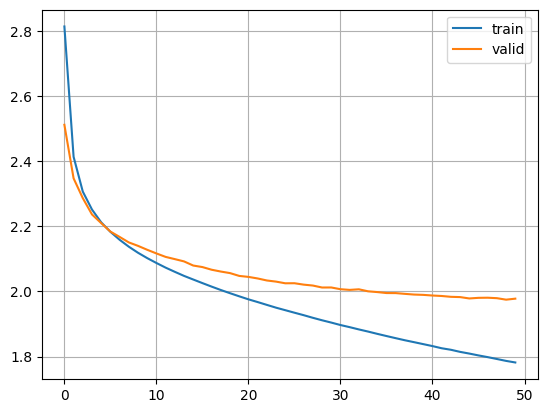

In [76]:
plt.figure()

plt.plot(train_losses, label='train')
plt.plot(valid_losses, label='valid')

plt.grid()
plt.legend()
plt.show()

In [77]:
for _ in range(10):
    name = rnn_encoder.generate_name(temperature=1.0)
    print(name)

maida
cherry
mykha
mancephid
gurnette
frodah
erzi
jaqustenc
shayno
shavon


# RNN Machine Translation

In [278]:
train_idx, valid_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42, stratify=df['gender'])
valid_idx, test_idx = train_test_split(valid_idx, test_size=0.5, random_state=42, stratify=df.iloc[valid_idx]['gender'])

In [79]:
X_train = torch.tensor(df.loc[train_idx, 'name_encoded'].tolist(), dtype=torch.long)
y_train = torch.tensor(df.loc[train_idx, 'ru_name_encoded'].tolist(), dtype=torch.long)

X_valid = torch.tensor(df.loc[valid_idx, 'name_encoded'].tolist(), dtype=torch.long)
y_valid = torch.tensor(df.loc[valid_idx, 'ru_name_encoded'].tolist(), dtype=torch.long)

X_test = torch.tensor(df.loc[test_idx, 'name_encoded'].tolist(), dtype=torch.long)
y_test = torch.tensor(df.loc[test_idx, 'ru_name_encoded'].tolist(), dtype=torch.long)

train_translation_dataset = TensorDataset(X_train, y_train)
valid_translation_dataset = TensorDataset(X_valid, y_valid)
test_translation_dataset = TensorDataset(X_test, y_test)

train_translation_loader = DataLoader(train_translation_dataset, batch_size=32, shuffle=True)
valid_translation_loader = DataLoader(valid_translation_dataset, batch_size=32, shuffle=False)
test_translation_loader = DataLoader(test_translation_dataset, batch_size=32, shuffle=False)

In [80]:
rnn_encoder.eval()

for param in rnn_encoder.parameters():
    param.requires_grad = False

In [99]:
class RNNDecoder(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, padding_idx=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=padding_idx)
        self.gru = nn.GRU(embedding_size, hidden_size, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden):
        embedded = self.embedding(x)
        outputs, hidden = self.gru(embedded, hidden)
        logits = self.output_layer(outputs)

        return logits, hidden

In [100]:
class RNNTranslator(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x, target):
        with torch.no_grad():
            _, encoder_outputs, encoder_hidden = self.encoder(x)

        decoder_input = target[:, :-1]
        decoder_logits, decoder_hidden = self.decoder(decoder_input, encoder_hidden)

        return decoder_logits, decoder_hidden

In [190]:
def train_translator(model, decoder, train_loader, valid_loader, epochs=50, stop=5, lr=3e-4):
    criterion = nn.CrossEntropyLoss(ignore_index=ru_char2id['<PAD>'])
    optimizer = torch.optim.Adam(decoder.parameters(), lr=lr)

    best_val_loss = float('inf')
    best_state = None
    epochs_without_upgrade = 0

    train_losses = []
    valid_losses = []

    for epoch in range(epochs):
        model.train()
        model.encoder.eval()

        total_loss = 0.0
        for X_batch, y_batch in train_loader:
            logits, _, _ = model(X_batch, y_batch)

            preds = logits.reshape(-1, logits.size(-1))
            targets = y_batch[:, 1:].reshape(-1)

            loss = criterion(preds, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

        avg_train_loss = total_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        model.eval()
        total_valid_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in valid_loader:
                logits, _, _ = model(X_batch, y_batch)
                preds = logits.reshape(-1, logits.size(-1))
                targets = y_batch[:, 1:].reshape(-1)

                loss = criterion(preds, targets)
                total_valid_loss += loss.item() * X_batch.size(0)

            avg_valid_loss = total_valid_loss / len(valid_loader.dataset)
            valid_losses.append(avg_valid_loss)

        print(f"epoch {epoch + 1}/{epochs}, train loss: {avg_train_loss:.4f}, valid loss: {avg_valid_loss:.4f}")

        if avg_valid_loss < best_val_loss:
            best_val_loss = avg_valid_loss
            best_state = {k: v.cpu().clone() for k, v in decoder.state_dict().items()}
            epochs_without_upgrade = 0
        else:
            epochs_without_upgrade += 1

        if epochs_without_upgrade >= stop:
            break

    decoder.load_state_dict(best_state)

    return train_losses, valid_losses, best_state

In [102]:
decoder = RNNDecoder(vocab_size=len(ru_char2id), embedding_size=32, hidden_size=128, padding_idx=ru_char2id['<PAD>'])
translator = RNNTranslator(rnn_encoder, decoder)
train_translation_losses, valid_translation_losses, best_decoder_state = train_translator(translator, decoder, train_translation_loader, valid_translation_loader)

epoch 1/50, train loss: 2.8568, valid loss: 2.5539
epoch 2/50, train loss: 2.4502, valid loss: 2.3450
epoch 3/50, train loss: 2.2775, valid loss: 2.2296
epoch 4/50, train loss: 2.1892, valid loss: 2.1664
epoch 5/50, train loss: 2.1374, valid loss: 2.1251
epoch 6/50, train loss: 2.0963, valid loss: 2.0863
epoch 7/50, train loss: 2.0598, valid loss: 2.0580
epoch 8/50, train loss: 2.0259, valid loss: 2.0251
epoch 9/50, train loss: 1.9943, valid loss: 1.9970
epoch 10/50, train loss: 1.9622, valid loss: 1.9705
epoch 11/50, train loss: 1.9330, valid loss: 1.9441
epoch 12/50, train loss: 1.9075, valid loss: 1.9200
epoch 13/50, train loss: 1.8827, valid loss: 1.9005
epoch 14/50, train loss: 1.8587, valid loss: 1.8853
epoch 15/50, train loss: 1.8367, valid loss: 1.8639
epoch 16/50, train loss: 1.8157, valid loss: 1.8463
epoch 17/50, train loss: 1.7973, valid loss: 1.8305
epoch 18/50, train loss: 1.7771, valid loss: 1.8139
epoch 19/50, train loss: 1.7578, valid loss: 1.8006
epoch 20/50, train lo

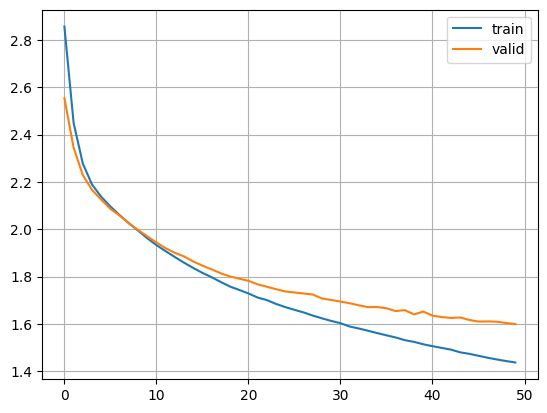

In [103]:
plt.figure()

plt.plot(train_translation_losses, label='train')
plt.plot(valid_translation_losses, label='valid')

plt.legend()
plt.grid()
plt.show()

In [104]:
def translate_name(model, name, max_len=13):
    model.eval()

    tokens = encode_tokens(pad_name(name), eng_char2id)
    tokens_t = torch.tensor([tokens], dtype=torch.long)
    with torch.no_grad():
        _, logits, hidden = model.encoder(tokens_t)
        curr_id = torch.tensor([[ru_char2id['<SOS>']]], dtype=torch.long)
        generated = []

        for _ in range(max_len):
            logits, hidden = model.decoder(curr_id, hidden)
            next_logits = logits[:, -1, :]
            next_id = torch.argmax(next_logits, dim=-1).item()

            if next_id == ru_char2id['<EOS>']:
                break
            if next_id != ru_char2id['<PAD>']:
                generated.append(next_id)
                
            curr_id = torch.tensor([[next_id]], dtype=torch.long)

    return "".join(ru_id2char[id] for id in generated)

In [ ]:
def print_translations(translator, idxs):
    for idx in idxs[:5]:
        original = df.loc[idx, 'name']
        target = df.loc[idx, 'translated']
        prediction = translate_name(translator, original)

        print(f"{original} - {prediction}, target: {target}")

In [106]:
print('train:\n')
print_translations(translator, train_idx)

train:

Elvis - алли, target: Элвис
Khloe - лин, target: Хлоя
Alpha - джайда, target: Альфа
Tanesha - джони, target: Танеша
Tennie - лени, target: Тенни


In [107]:
print('valid:\n')
print_translations(translator, valid_idx)

valid:

Santino - джейни, target: Сантино
Terrie - марри, target: Терри
Jennings - мантер, target: Дженнингс
Ashlie - карли, target: Эшли
Clint - элвис, target: Клинт


In [195]:
def evaluate_translation_perplexity(model, test_loader):
    model.eval()

    criterion = nn.CrossEntropyLoss(ignore_index=ru_char2id['<PAD>'])

    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:

            logits, _, _ = model(X_batch, y_batch)

            preds = logits.reshape(-1, logits.size(-1))
            targets = y_batch[:, 1:].reshape(-1)

            loss = criterion(preds, targets)

            total_loss += loss.item() * X_batch.size(0)
            total_samples += X_batch.size(0)

    avg_loss = total_loss / total_samples
    perplexity = np.exp(avg_loss)

    return avg_loss, perplexity

In [109]:
loss_translation, perplexity_translation = evaluate_translation_perplexity(translator, test_translation_loader)
print(loss_translation)
print(perplexity_translation)

1.5532688426408796
4.726896436486871


# Attention Machine Translation

In [112]:
class RNNDecoderAt(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, padding_idx=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=padding_idx)
        self.gru = nn.GRU(embedding_size + hidden_size, hidden_size, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden):
        embedded = self.embedding(x)
        outputs, hidden = self.gru(embedded, hidden)
        logits = self.output_layer(outputs)

        return logits, hidden

In [119]:
class RNNAttention(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.vocab_size = encoder.vocab_size
        self.embedding_size = encoder.embedding_size
        self.hidden_size = encoder.hidden_size
        
        self.encoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.decoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.context_attention = nn.Tanh()

        self.attention_score = nn.Linear(self.hidden_size, 1)

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x, target):
        _, encoder_outputs, hidden_encoder = self.encoder(x)
        values = target[:, :-1]
        embedded = self.decoder.embedding(values)
        decoder_hidden = hidden_encoder
        decoder_outputs = []

        for t in range(values.size(1)):
            decoder_input = embedded[:, t, :]
            decoder_hidden_last = decoder_hidden[-1]

            encoded_context = self.encoder_context(encoder_outputs)
            decoder_context = self.decoder_context(decoder_hidden_last).unsqueeze(1)

            attention = self.context_attention(encoded_context + decoder_context)
            score = self.attention_score(attention).squeeze(-1)
            attention_weights = torch.softmax(score, dim=-1)
            context_vector = torch.sum(attention_weights.unsqueeze(-1) * encoder_outputs, dim=1)

            decoder_input = torch.cat([decoder_input, context_vector], dim=-1)

            decoder_output, decoder_hidden = self.decoder.gru(decoder_input.unsqueeze(1), decoder_hidden)

            decoder_logit = self.decoder.output_layer(decoder_output)

            decoder_outputs.append(decoder_logit)

        decoder_logits = torch.cat(decoder_outputs, dim=1)

        return decoder_logits, decoder_hidden

In [121]:
decoder_attention = RNNDecoderAt(vocab_size=len(ru_char2id), embedding_size=32, hidden_size=128, padding_idx=ru_char2id['<PAD>'])
translator_attention = RNNAttention(rnn_encoder, decoder_attention)
train_translation_losses_at, valid_translation_losses_at, best_decoder_state_at = train_translator(translator_attention, decoder_attention, train_translation_loader, valid_translation_loader)

epoch 1/50, train loss: 2.7197, valid loss: 2.4183
epoch 2/50, train loss: 2.2499, valid loss: 2.0839
epoch 3/50, train loss: 1.9655, valid loss: 1.8605
epoch 4/50, train loss: 1.7776, valid loss: 1.6990
epoch 5/50, train loss: 1.6343, valid loss: 1.5776
epoch 6/50, train loss: 1.5193, valid loss: 1.4792
epoch 7/50, train loss: 1.4242, valid loss: 1.3927
epoch 8/50, train loss: 1.3430, valid loss: 1.3201
epoch 9/50, train loss: 1.2753, valid loss: 1.2600
epoch 10/50, train loss: 1.2129, valid loss: 1.2082
epoch 11/50, train loss: 1.1616, valid loss: 1.1674
epoch 12/50, train loss: 1.1141, valid loss: 1.1171
epoch 13/50, train loss: 1.0659, valid loss: 1.0728
epoch 14/50, train loss: 1.0238, valid loss: 1.0302
epoch 15/50, train loss: 0.9861, valid loss: 1.0012
epoch 16/50, train loss: 0.9517, valid loss: 0.9643
epoch 17/50, train loss: 0.9158, valid loss: 0.9401
epoch 18/50, train loss: 0.8870, valid loss: 0.9167
epoch 19/50, train loss: 0.8601, valid loss: 0.8834
epoch 20/50, train lo

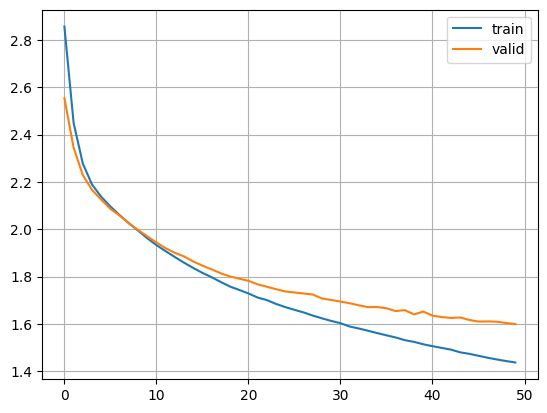

In [122]:
plt.figure()

plt.plot(train_translation_losses, label='train')
plt.plot(valid_translation_losses, label='valid')

plt.grid()
plt.legend()
plt.show()

In [126]:
def translate_name_attention(model, name, max_len=13):
    model.eval()

    tokens = encode_tokens(pad_name(name), eng_char2id)
    tokens_t = torch.tensor([tokens], dtype=torch.long)
    with torch.no_grad():
        _, encoder_outputs, hidden = model.encoder(tokens_t)
        curr_id = torch.tensor([[ru_char2id['<SOS>']]], dtype=torch.long)
        generated = []

        for _ in range(max_len):
            embedded = model.decoder.embedding(curr_id)
            decoder_input = embedded[:, 0, :]

            decoder_hidden_last = hidden[-1]
            encoded_context = model.encoder_context(encoder_outputs)
            decoder_context = model.decoder_context(decoder_hidden_last).unsqueeze(1)
            attention = model.context_attention(encoded_context + decoder_context)
            score = model.attention_score(attention).squeeze(-1)
            attention_weights = torch.softmax(score, dim=-1)
            context_vector = torch.sum(attention_weights.unsqueeze(-1) * encoder_outputs, dim=1)

            decoder_input = torch.cat([decoder_input, context_vector], dim=-1)
            decoder_output, hidden = model.decoder.gru(decoder_input.unsqueeze(1), hidden)

            logits = model.decoder.output_layer(decoder_output)
            next_logits = logits[:, -1, :]
            next_id = torch.argmax(next_logits, dim=-1).item()

            if next_id == ru_char2id['<EOS>']:
                break
            if next_id != ru_char2id['<PAD>']:
                generated.append(next_id)
                
            curr_id = torch.tensor([[next_id]], dtype=torch.long)

    return "".join(ru_id2char[id] for id in generated)

def print_translations_at(translator, idxs):
    for idx in idxs[:5]:
        original = df.loc[idx, 'name']
        target = df.loc[idx, 'translated']
        prediction = translate_name_attention(translator, original)

        print(f"{original} - {prediction}, target: {target}")

In [129]:
print('train:\n')
print_translations_at(translator_attention, train_idx)

print('\nvalid:\n')
print_translations_at(translator_attention, valid_idx)

train:

Elvis - эльм, target: Элвис
Khloe - кело, target: Хлоя
Alpha - альфа, target: Альфа
Tanesha - тана, target: Танеша
Tennie - тенни, target: Тенни

valid:

Santino - сантон, target: Сантино
Terrie - терри, target: Терри
Jennings - дженнин, target: Дженнингс
Ashlie - эсил, target: Эшли
Clint - клитн, target: Клинт


In [130]:
loss_translation_at, perplexity_translation_at = evaluate_translation_perplexity(translator_attention, test_translation_loader)
print(loss_translation_at)
print(perplexity_translation_at)

0.5789808182589775
1.784219060284754


compare results: 

# Positional Encoding

## a. Implement position encoding using sine and cosine:

In [134]:
class PositionalEncoder(nn.Module):
    def __init__(self, embedding_size, max_len=13):
        super().__init__()
        pe = torch.zeros(max_len, embedding_size)

        positions = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)

        temp = torch.exp(torch.arange(0, embedding_size, 2).float() * (-np.log(10000.0)/embedding_size))

        pe[:, 0::2] = torch.sin(positions * temp)
        pe[:, 1::2] = torch.cos(positions * temp)

        self.register_buffer("pe", pe)

    def forward(self, x, start_pos=0):
        return x + self.pe[start_pos:start_pos + x.size(1)].unsqueeze(0)

In [145]:
class RNNEncoderPE(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128):
        super().__init__()

        self.vocab_size = vocab_size
        self.embedding_size = embedding_size
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=eng_char2id['<PAD>'])
        self.encoding = PositionalEncoder(embedding_size, max_len=max_len)
        self.gru = nn.GRU(embedding_size, hidden_size, num_layers=1, batch_first=True)
        self.outputs_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        embedded = self.embedding(x)
        embedded = self.encoding(embedded)
        if hidden is None:
            outputs, hidden = self.gru(embedded)
        else:
            outputs, hidden = self.gru(embedded, hidden)
        logits = self.outputs_layer(outputs)
        return logits, outputs, hidden  
    
    def generate_name(self, temperature=1.0, max_len=13):
        self.eval()

        start_id = eng_char2id['<SOS>']
        end_id = eng_char2id['<EOS>']

        curr_id = torch.tensor([[start_id]], dtype=torch.long)
        generate_ids = [start_id]
        hidden = None

        for _ in range(max_len):
            outputs = self(curr_id, hidden)
            hidden = outputs[2]
            logits = outputs[0][:, -1, :]
            logits = logits / temperature

            probs = torch.softmax(logits, dim=-1)
            next_letter = torch.multinomial(probs, num_samples=1).item()

            if next_letter == end_id:
                break

            generate_ids.append(next_letter)
            curr_id = torch.tensor([[next_letter]], dtype=torch.long)

        return ''.join(eng_id2char[letter] for letter in generate_ids[1:])


class RNNDecoderPE(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, padding_idx=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=padding_idx)
        self.positional_encoding = PositionalEncoder(embedding_size, max_len)
        self.gru = nn.GRU(embedding_size + hidden_size, hidden_size, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden):
        embedded = self.embedding(x)
        embedded = self.positional_encoding(embedded)
        outputs, hidden = self.gru(embedded, hidden)
        logits = self.output_layer(outputs)

        return logits, hidden


class RNNAttentionPE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.vocab_size = encoder.vocab_size
        self.embedding_size = encoder.embedding_size
        self.hidden_size = encoder.hidden_size
        
        self.encoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.decoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.context_attention = nn.Tanh()

        self.attention_score = nn.Linear(self.hidden_size, 1)

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x, target):
        _, encoder_outputs, hidden_encoder = self.encoder(x)
        values = target[:, :-1]
        embedded = self.decoder.embedding(values)
        decoder_hidden = hidden_encoder
        decoder_outputs = []

        for t in range(values.size(1)):
            cur_embedded = embedded[:, t, :]
            decoder_input = self.decoder.positional_encoding(cur_embedded.unsqueeze(1), start_pos=t).squeeze(1)
            decoder_hidden_last = decoder_hidden[-1]

            encoded_context = self.encoder_context(encoder_outputs)
            decoder_context = self.decoder_context(decoder_hidden_last).unsqueeze(1)

            attention = self.context_attention(encoded_context + decoder_context)
            score = self.attention_score(attention).squeeze(-1)
            attention_weights = torch.softmax(score, dim=-1)
            context_vector = torch.sum(attention_weights.unsqueeze(-1) * encoder_outputs, dim=1)

            decoder_input = torch.cat([decoder_input, context_vector], dim=-1)

            decoder_output, decoder_hidden = self.decoder.gru(decoder_input.unsqueeze(1), decoder_hidden)

            decoder_logit = self.decoder.output_layer(decoder_output)

            decoder_outputs.append(decoder_logit)

        decoder_logits = torch.cat(decoder_outputs, dim=1)

        return decoder_logits, decoder_hidden

In [146]:
rnn_encoder_pe = RNNEncoderPE(vocab_size=29)

train_losses_pe, valid_losses_pe, best_state_rnn_encoder_pe = train_model(rnn_encoder_pe, train_loader, valid_loader)

epoch 1/50, train Loss: 2.7497, valid Loss: 2.5080
epoch 2/50, train Loss: 2.4290, valid Loss: 2.3683
epoch 3/50, train Loss: 2.3270, valid Loss: 2.3009
epoch 4/50, train Loss: 2.2684, valid Loss: 2.2521
epoch 5/50, train Loss: 2.2258, valid Loss: 2.2183
epoch 6/50, train Loss: 2.1933, valid Loss: 2.1954
epoch 7/50, train Loss: 2.1659, valid Loss: 2.1739
epoch 8/50, train Loss: 2.1432, valid Loss: 2.1603
epoch 9/50, train Loss: 2.1240, valid Loss: 2.1440
epoch 10/50, train Loss: 2.1067, valid Loss: 2.1338
epoch 11/50, train Loss: 2.0917, valid Loss: 2.1192
epoch 12/50, train Loss: 2.0770, valid Loss: 2.1108
epoch 13/50, train Loss: 2.0637, valid Loss: 2.0989
epoch 14/50, train Loss: 2.0509, valid Loss: 2.0864
epoch 15/50, train Loss: 2.0381, valid Loss: 2.0804
epoch 16/50, train Loss: 2.0278, valid Loss: 2.0731
epoch 17/50, train Loss: 2.0174, valid Loss: 2.0651
epoch 18/50, train Loss: 2.0068, valid Loss: 2.0585
epoch 19/50, train Loss: 1.9969, valid Loss: 2.0549
epoch 20/50, train Lo

In [147]:
for param in rnn_encoder_pe.parameters():
    param.requires_grad = False

decoder_attention_pe = RNNDecoderPE(vocab_size=len(ru_char2id), embedding_size=32, hidden_size=128, padding_idx=ru_char2id['<PAD>'])
translator_attention_pe = RNNAttentionPE(rnn_encoder_pe, decoder_attention_pe)
train_translation_losses_at_pe, valid_translation_losses_at_pe, best_decoder_state_at_pe = train_translator(translator_attention_pe, decoder_attention_pe, train_translation_loader, valid_translation_loader)

epoch 1/50, train loss: 2.7295, valid loss: 2.4524
epoch 2/50, train loss: 2.2905, valid loss: 2.1238
epoch 3/50, train loss: 2.0021, valid loss: 1.8673
epoch 4/50, train loss: 1.7840, valid loss: 1.6779
epoch 5/50, train loss: 1.6189, valid loss: 1.5402
epoch 6/50, train loss: 1.4878, valid loss: 1.4265
epoch 7/50, train loss: 1.3815, valid loss: 1.3216
epoch 8/50, train loss: 1.2906, valid loss: 1.2425
epoch 9/50, train loss: 1.2155, valid loss: 1.1895
epoch 10/50, train loss: 1.1477, valid loss: 1.1393
epoch 11/50, train loss: 1.0933, valid loss: 1.0949
epoch 12/50, train loss: 1.0437, valid loss: 1.0354
epoch 13/50, train loss: 0.9980, valid loss: 0.9931
epoch 14/50, train loss: 0.9564, valid loss: 0.9510
epoch 15/50, train loss: 0.9204, valid loss: 0.9234
epoch 16/50, train loss: 0.8855, valid loss: 0.8877
epoch 17/50, train loss: 0.8545, valid loss: 0.8616
epoch 18/50, train loss: 0.8282, valid loss: 0.8530
epoch 19/50, train loss: 0.8010, valid loss: 0.8179
epoch 20/50, train lo

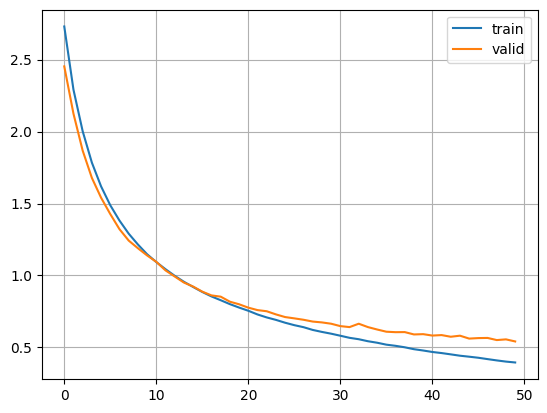

In [148]:
plt.figure()

plt.plot(train_translation_losses_at_pe, label='train')
plt.plot(valid_translation_losses_at_pe, label='valid')

plt.grid()
plt.legend()
plt.show()

In [149]:
print('train:\n')
print_translations_at(translator_attention_pe, train_idx)

print('\nvalid:\n')
print_translations_at(translator_attention_pe, valid_idx)

train:

Elvis - лести, target: Элвис
Khloe - клоф, target: Хлоя
Alpha - альфт, target: Альфа
Tanesha - тейтт, target: Танеша
Tennie - тейнз, target: Тенни

valid:

Santino - стейтс, target: Сантино
Terrie - терри, target: Терри
Jennings - дженнжитт, target: Дженнингс
Ashlie - аксли, target: Эшли
Clint - клитт, target: Клинт


In [150]:
loss_translation_at_pe, perplexity_translation_at_pe = evaluate_translation_perplexity(translator_attention_pe, test_translation_loader)
print(loss_translation_at_pe)
print(perplexity_translation_at_pe)

0.5846387394058318
1.7943426432472314


## b. Implement position encoding with trainable weights:

In [151]:
class TrainablePositionalEncoder(nn.Module):
    def __init__(self, embedding_size, max_len=13):
        super().__init__()
        self.pe = nn.Parameter(torch.randn(1, max_len, embedding_size))

    def forward(self, x, start_pos=0):
        return x + self.pe[:, start_pos:start_pos + x.size(1), :]

In [212]:
class RNNEncoderTPE(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128):
        super().__init__()

        self.vocab_size = vocab_size
        self.embedding_size = embedding_size
        self.hidden_size = hidden_size

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=eng_char2id['<PAD>'])
        self.positional_encoding = TrainablePositionalEncoder(embedding_size, max_len=max_len)
        self.gru = nn.GRU(embedding_size, hidden_size, num_layers=1, batch_first=True)
        self.outputs_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden=None):
        embedded = self.embedding(x)
        embedded = self.positional_encoding(embedded)
        if hidden is None:
            outputs, hidden = self.gru(embedded)
        else:
            outputs, hidden = self.gru(embedded, hidden)
        logits = self.outputs_layer(outputs)
        return logits, outputs, hidden  
    
    def generate_name(self, temperature=1.0, max_len=13):
        self.eval()

        start_id = eng_char2id['<SOS>']
        end_id = eng_char2id['<EOS>']

        curr_id = torch.tensor([[start_id]], dtype=torch.long)
        generate_ids = [start_id]
        hidden = None

        for _ in range(max_len):
            outputs = self(curr_id, hidden)
            hidden = outputs[2]
            logits = outputs[0][:, -1, :]
            logits = logits / temperature

            probs = torch.softmax(logits, dim=-1)
            next_letter = torch.multinomial(probs, num_samples=1).item()

            if next_letter == end_id:
                break

            generate_ids.append(next_letter)
            curr_id = torch.tensor([[next_letter]], dtype=torch.long)

        return ''.join(eng_id2char[letter] for letter in generate_ids[1:])


class RNNDecoderTPE(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, padding_idx=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=padding_idx)
        self.positional_encoding = TrainablePositionalEncoder(embedding_size, max_len)
        self.gru = nn.GRU(embedding_size + hidden_size, hidden_size, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden):
        embedded = self.embedding(x)
        embedded = self.positional_encoding(embedded)
        outputs, hidden = self.gru(embedded, hidden)
        logits = self.output_layer(outputs)

        return logits, hidden


class RNNAttentionTPE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.vocab_size = encoder.vocab_size
        self.embedding_size = encoder.embedding_size
        self.hidden_size = encoder.hidden_size
        
        self.encoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.decoder_context = nn.Linear(self.hidden_size, self.hidden_size)
        self.context_attention = nn.Tanh()

        self.attention_score = nn.Linear(self.hidden_size, 1)

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x, target):
        _, encoder_outputs, hidden_encoder = self.encoder(x)
        values = target[:, :-1]
        embedded = self.decoder.embedding(values)
        decoder_hidden = hidden_encoder
        decoder_outputs = []
        attention_matrices = []

        for t in range(values.size(1)):
            cur_embedded = embedded[:, t, :]
            decoder_input = self.decoder.positional_encoding(cur_embedded.unsqueeze(1), start_pos=t).squeeze(1)
            decoder_hidden_last = decoder_hidden[-1]

            encoded_context = self.encoder_context(encoder_outputs)
            decoder_context = self.decoder_context(decoder_hidden_last).unsqueeze(1)

            attention = self.context_attention(encoded_context + decoder_context)
            score = self.attention_score(attention).squeeze(-1)
            encoder_pad_mask = x == eng_char2id['<PAD>']
            score = score.masked_fill(
                encoder_pad_mask,
                float('-inf')
            )
            attention_weights = torch.softmax(score, dim=-1)
            context_vector = torch.sum(attention_weights.unsqueeze(-1) * encoder_outputs, dim=1)

            decoder_input = torch.cat([decoder_input, context_vector], dim=-1)

            decoder_output, decoder_hidden = self.decoder.gru(decoder_input.unsqueeze(1), decoder_hidden)

            decoder_logit = self.decoder.output_layer(decoder_output)

            decoder_outputs.append(decoder_logit)
            attention_matrices.append(attention_weights)

        decoder_logits = torch.cat(decoder_outputs, dim=1)
        attention_matrices = torch.stack(attention_matrices, dim=1)

        return decoder_logits, decoder_hidden, attention_matrices

In [234]:
rnn_encoder_tpe = RNNEncoderTPE(vocab_size=29)

train_losses_tpe, valid_losses_tpe, best_state_rnn_encoder_tpe = train_model(rnn_encoder_tpe, train_loader, valid_loader, epochs=50)

epoch 1/50, train Loss: 2.7570, valid Loss: 2.5100
epoch 2/50, train Loss: 2.4178, valid Loss: 2.3636
epoch 3/50, train Loss: 2.3191, valid Loss: 2.2962
epoch 4/50, train Loss: 2.2650, valid Loss: 2.2536
epoch 5/50, train Loss: 2.2264, valid Loss: 2.2203
epoch 6/50, train Loss: 2.1956, valid Loss: 2.1939
epoch 7/50, train Loss: 2.1712, valid Loss: 2.1763
epoch 8/50, train Loss: 2.1487, valid Loss: 2.1572
epoch 9/50, train Loss: 2.1297, valid Loss: 2.1457
epoch 10/50, train Loss: 2.1127, valid Loss: 2.1282
epoch 11/50, train Loss: 2.0969, valid Loss: 2.1197
epoch 12/50, train Loss: 2.0827, valid Loss: 2.1083
epoch 13/50, train Loss: 2.0684, valid Loss: 2.1004
epoch 14/50, train Loss: 2.0556, valid Loss: 2.0937
epoch 15/50, train Loss: 2.0436, valid Loss: 2.0832
epoch 16/50, train Loss: 2.0320, valid Loss: 2.0760
epoch 17/50, train Loss: 2.0203, valid Loss: 2.0690
epoch 18/50, train Loss: 2.0097, valid Loss: 2.0642
epoch 19/50, train Loss: 1.9995, valid Loss: 2.0553
epoch 20/50, train Lo

In [235]:
for param in rnn_encoder_tpe.parameters():
    param.requires_grad = False

decoder_attention_tpe = RNNDecoderTPE(vocab_size=len(ru_char2id), embedding_size=32, hidden_size=128, padding_idx=ru_char2id['<PAD>'])
translator_attention_tpe = RNNAttentionTPE(rnn_encoder_tpe, decoder_attention_tpe)
train_translation_losses_at_tpe, valid_translation_losses_at_tpe, best_decoder_state_at_tpe = train_translator(translator_attention_tpe, decoder_attention_tpe, train_translation_loader, valid_translation_loader, epochs=50)

epoch 1/50, train loss: 2.7181, valid loss: 2.3943
epoch 2/50, train loss: 2.2127, valid loss: 2.0333
epoch 3/50, train loss: 1.8913, valid loss: 1.7562
epoch 4/50, train loss: 1.6418, valid loss: 1.5493
epoch 5/50, train loss: 1.4560, valid loss: 1.3981
epoch 6/50, train loss: 1.3148, valid loss: 1.2797
epoch 7/50, train loss: 1.2001, valid loss: 1.1701
epoch 8/50, train loss: 1.1116, valid loss: 1.0954
epoch 9/50, train loss: 1.0331, valid loss: 1.0247
epoch 10/50, train loss: 0.9694, valid loss: 0.9690
epoch 11/50, train loss: 0.9128, valid loss: 0.9273
epoch 12/50, train loss: 0.8632, valid loss: 0.8911
epoch 13/50, train loss: 0.8198, valid loss: 0.8540
epoch 14/50, train loss: 0.7817, valid loss: 0.8127
epoch 15/50, train loss: 0.7468, valid loss: 0.7950
epoch 16/50, train loss: 0.7181, valid loss: 0.7683
epoch 17/50, train loss: 0.6893, valid loss: 0.7603
epoch 18/50, train loss: 0.6628, valid loss: 0.7196
epoch 19/50, train loss: 0.6405, valid loss: 0.7073
epoch 20/50, train lo

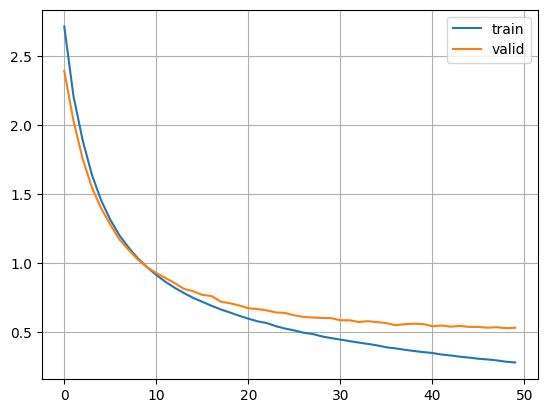

In [236]:
plt.figure()

plt.plot(train_translation_losses_at_tpe, label='train')
plt.plot(valid_translation_losses_at_tpe, label='valid')

plt.grid()
plt.legend()
plt.show()

In [263]:
print('train:\n')
print_translations_at(translator_attention_tpe, train_idx)

print('\nvalid:\n')
print_translations_at(translator_attention_tpe, valid_idx)

train:

Elvis - лемсильтексур, target: Элвис
Khloe - лемонитлькект, target: Хлоя
Alpha - лемить, target: Альфа
Tanesha - лексинтейн, target: Танеша
Tennie - лензисенеттин, target: Тенни

valid:

Santino - леминтинг, target: Сантино
Terrie - лерекитник, target: Терри
Jennings - ленсснинг, target: Дженнингс
Ashlie - лезилименгише, target: Эшли
Clint - лестиннит, target: Клинт


In [238]:
loss_translation_at_tpe, perplexity_translation_at_tpe = evaluate_translation_perplexity(translator_attention_tpe, test_translation_loader)
print(loss_translation_at_tpe)
print(perplexity_translation_at_tpe)

0.5655957729415556
1.7604963264188074


In [239]:
example_idx = 0

x_example = X_valid[example_idx:example_idx + 1]
y_example = y_valid[example_idx:example_idx + 1]

with torch.no_grad():
    _, _, attention = translator_attention_tpe(
        x_example,
        y_example
    )

attention = attention.squeeze(0)

print("English:", ''.join(eng_id2char[int(i)] for i in x_example[0]))
print("Russian:", ''.join(ru_id2char[int(i)] for i in y_example[0]))

English: <SOS>santino<EOS><PAD><PAD><PAD><PAD>
Russian: <SOS>сантино<EOS><PAD><PAD><PAD><PAD><PAD><PAD>


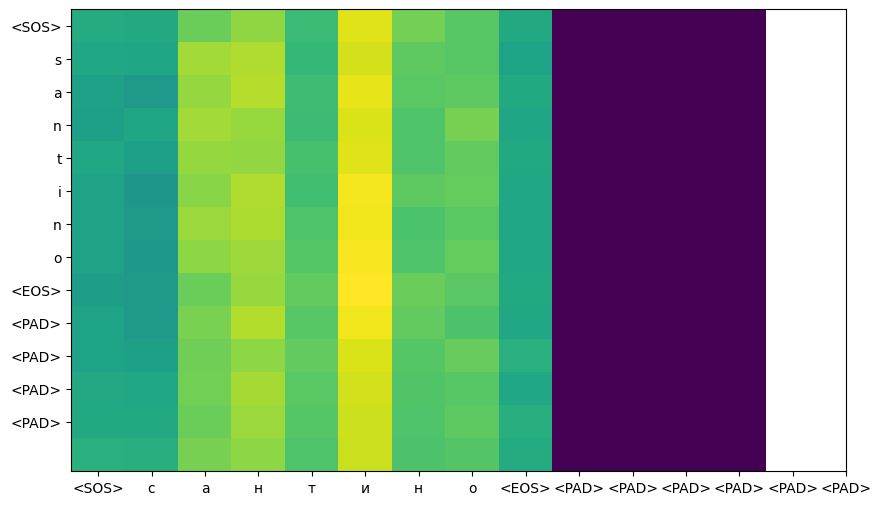

In [240]:
encoder_tokens = [eng_id2char[int(i)] for i in x_example[0]]
decoder_tokens = [ru_id2char[int(i)] for i in y_example[0]]

plt.figure(figsize=(10, 6))
plt.imshow(attention.cpu().numpy(), aspect='auto')
plt.xticks(range(len(decoder_tokens)), decoder_tokens)
plt.yticks(range(len(encoder_tokens)), encoder_tokens)
plt.show()

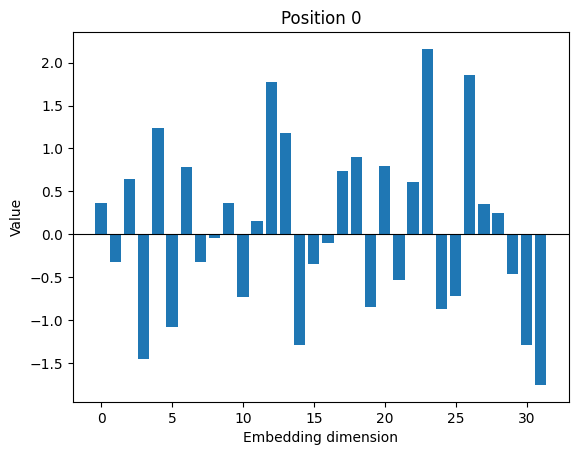

In [241]:
pe = rnn_encoder_tpe.positional_encoding.pe.detach().cpu().squeeze(0)

pos = 0

values = pe[pos].numpy()

x = range(len(values))

plt.bar(x, values)

plt.axhline(0, color='black', linewidth=0.8)

plt.xlabel("Embedding dimension")
plt.ylabel("Value")
plt.title(f"Position {pos}")
plt.show()

в общем то помимо очевидного отличия что мне было гораздо проще реализовать трейнбл позишнл энкодинг заместо с синусом и косинусом разница в лишних вычислениях а значит и в производительности, ну и трейнбл более адаптивен под датасет, хоть отсюда и следует риск переобучения

# Multi-head Attention Machine Translation

In [242]:
class RNNDecoderHead(nn.Module):
    def __init__(self, vocab_size, embedding_size=32, hidden_size=128, padding_idx=None):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=padding_idx)
        self.positional_encoding = TrainablePositionalEncoder(embedding_size, max_len)
        self.gru = nn.GRU(embedding_size + hidden_size * 3, hidden_size, num_layers=1, batch_first=True)
        self.output_layer = nn.Linear(hidden_size, vocab_size)

    def forward(self, x, hidden, context, embedded=False):
        if not embedded:
            x = self.embedding(x)
            x = self.positional_encoding(x)

        decoder_input = torch.cat([x, context], dim=-1)
        outputs, hidden = self.gru(decoder_input, hidden)
        logits = self.output_layer(outputs)

        return logits, hidden

class RNNHeadAttention(nn.Module):
    def __init__(self, encoder, decoder, n_heads=3):
        super().__init__()
        self.vocab_size = encoder.vocab_size
        self.embedding_size = encoder.embedding_size
        self.hidden_size = encoder.hidden_size
        self.n_heads = n_heads
        
        self.encoder_context = nn.ModuleList([nn.Linear(self.hidden_size, self.hidden_size) for _ in range(n_heads)])
        self.decoder_context = nn.ModuleList([nn.Linear(self.hidden_size, self.hidden_size) for _ in range(n_heads)])
        self.context_attention = nn.Tanh()

        self.attention_score = nn.ModuleList([nn.Linear(self.hidden_size, 1) for _ in range(n_heads)])

        self.encoder = encoder
        self.decoder = decoder

    def forward(self, x, target):
        _, encoder_outputs, hidden_encoder = self.encoder(x)
        values = target[:, :-1]
        embedded = self.decoder.embedding(values)
        decoder_hidden = hidden_encoder
        decoder_outputs = []
        attention_matrices = []

        for t in range(values.size(1)):
            cur_embedded = embedded[:, t, :]
            decoder_input = self.decoder.positional_encoding(cur_embedded.unsqueeze(1), start_pos=t).squeeze(1)
            decoder_hidden_last = decoder_hidden[-1]

            heads_weights = []
            heads_contexts = []
            for h in range(self.n_heads):
                encoded_context = self.encoder_context[h](encoder_outputs)
                decoder_context = self.decoder_context[h](decoder_hidden_last).unsqueeze(1)

                attention = self.context_attention(encoded_context + decoder_context)
                score = self.attention_score[h](attention).squeeze(-1)
                attention_weights = torch.softmax(score, dim=-1)
                context_vector = torch.sum(attention_weights.unsqueeze(-1) * encoder_outputs, dim=1)

                heads_weights.append(attention_weights)
                heads_contexts.append(context_vector)

            context_vector = torch.cat(heads_contexts, dim=1)
            decoder_input = decoder_input.unsqueeze(1)
            context_vector = context_vector.unsqueeze(1)
 
            decoder_output, decoder_hidden = self.decoder(decoder_input, decoder_hidden, context_vector, embedded=True)

            decoder_outputs.append(decoder_output)

            attention_matrices.append(torch.stack(heads_weights, dim=1))

        decoder_logits = torch.cat(decoder_outputs, dim=1)

        attention_matrices = torch.stack(attention_matrices, dim=1)

        return (decoder_logits, decoder_hidden, attention_matrices)

In [245]:
rnn_head_decoder = RNNDecoderHead(vocab_size=len(ru_char2id), embedding_size=32, hidden_size=128, padding_idx=ru_char2id['<PAD>'])
rnn_head_attention = RNNHeadAttention(rnn_encoder_tpe, rnn_head_decoder, n_heads=3)

In [ ]:
rnn_head_attention.encoder.eval()

for param in rnn_head_attention.encoder.parameters():
    param.requires_grad = False

In [247]:
sample_idx = 0

sample_x = X_valid[sample_idx:sample_idx + 1]
sample_y = y_valid[sample_idx:sample_idx + 1]

In [250]:
def plot_attention(model, x, target, epoch):
    model.eval()
    with torch.no_grad():
        _, _, attention = model(x, target)
    attention = attention[0].numpy()

    enc_tok = [eng_id2char[int(i)] for i in x[0]]
    dec_tok = [ru_id2char[int(i)] for i in target[0, 1:]]

    n_heads = attention.shape[1]
    fig, axes = plt.subplots(1, n_heads, figsize=(18, 5))

    for h, ax in enumerate(axes):
        ax.imshow(attention[:, h, :], aspect='auto')
        ax.set(title=f'Head {h + 1}', xlabel='Encoder', ylabel='Decoder')
        ax.set_xticks(range(len(enc_tok)), enc_tok)
        ax.set_yticks(range(len(dec_tok)), dec_tok)

    plt.suptitle(f'Attention matrix, epoch {epoch}')
    plt.tight_layout()
    plt.show()

In [ ]:
def train_multihead_attention(model, train_loader, valid_loader, X_sample, y_sample, epochs=50, lr=3e-4, stop=5, print_every=5):
    criterion = nn.CrossEntropyLoss(ignore_index=ru_char2id['<PAD>'])
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    best_valid_loss, best_state, patience = float('inf'), None, 0
    train_losses, valid_losses = [], []

    def run_epoch(loader):
        total = 0.0
        for X, y in loader:
            logits, _, _ = model(X, y)
            loss = criterion(logits.reshape(-1, logits.size(-1)), y[:, 1:].reshape(-1))
            if model.training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total += loss.item() * X.size(0)
        return total / len(loader.dataset)

    for epoch in range(epochs):
        model.train(); model.encoder.eval()
        with torch.enable_grad():
            tr_loss = run_epoch(train_loader)

        model.eval()
        with torch.no_grad():
            vl_loss = run_epoch(valid_loader)

        train_losses.append(tr_loss); valid_losses.append(vl_loss)

        if vl_loss < best_valid_loss:
            best_valid_loss, patience = vl_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience += 1

        print(f"epoch {epoch+1}/{epochs}, train: {tr_loss:.4f}, valid: {vl_loss:.4f}")

        if (epoch + 1) % print_every == 0:
            plot_attention(model, X_sample, y_sample, epoch + 1)

        if patience >= stop:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return train_losses, valid_losses, best_state

epoch 1/50, train: 2.6042, valid: 2.1001
epoch 2/50, train: 1.5943, valid: 1.1442
epoch 3/50, train: 0.9203, valid: 0.7417
epoch 4/50, train: 0.6676, valid: 0.5894
epoch 5/50, train: 0.5512, valid: 0.5132


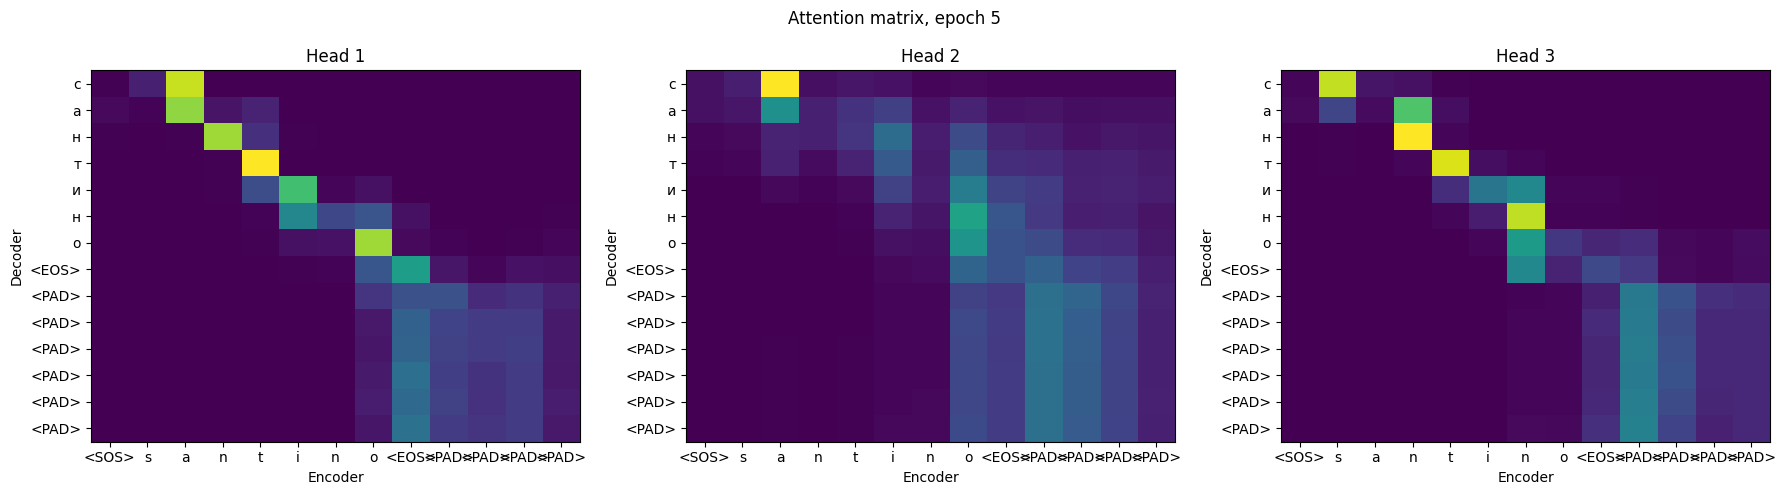

epoch 6/50, train: 0.4748, valid: 0.4575
epoch 7/50, train: 0.4220, valid: 0.4174
epoch 8/50, train: 0.3828, valid: 0.3858
epoch 9/50, train: 0.3505, valid: 0.3637
epoch 10/50, train: 0.3248, valid: 0.3774


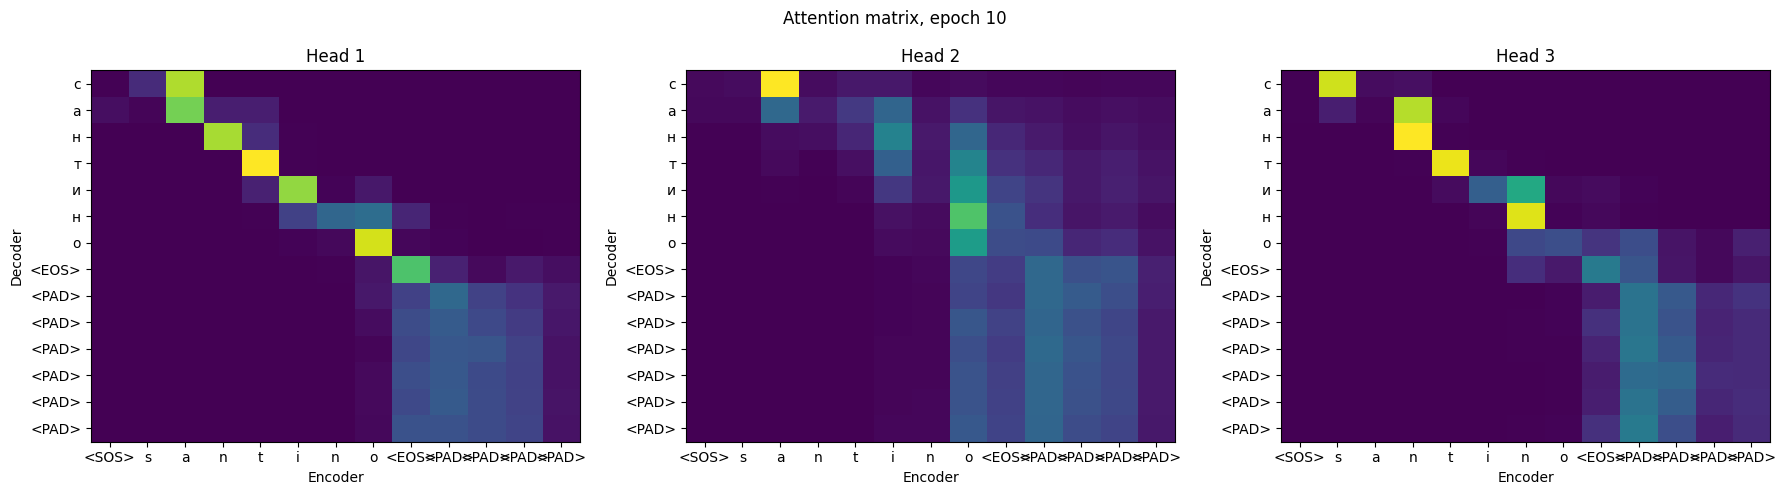

epoch 11/50, train: 0.3018, valid: 0.3343
epoch 12/50, train: 0.2848, valid: 0.3212
epoch 13/50, train: 0.2647, valid: 0.3148
epoch 14/50, train: 0.2509, valid: 0.3094
epoch 15/50, train: 0.2394, valid: 0.3013


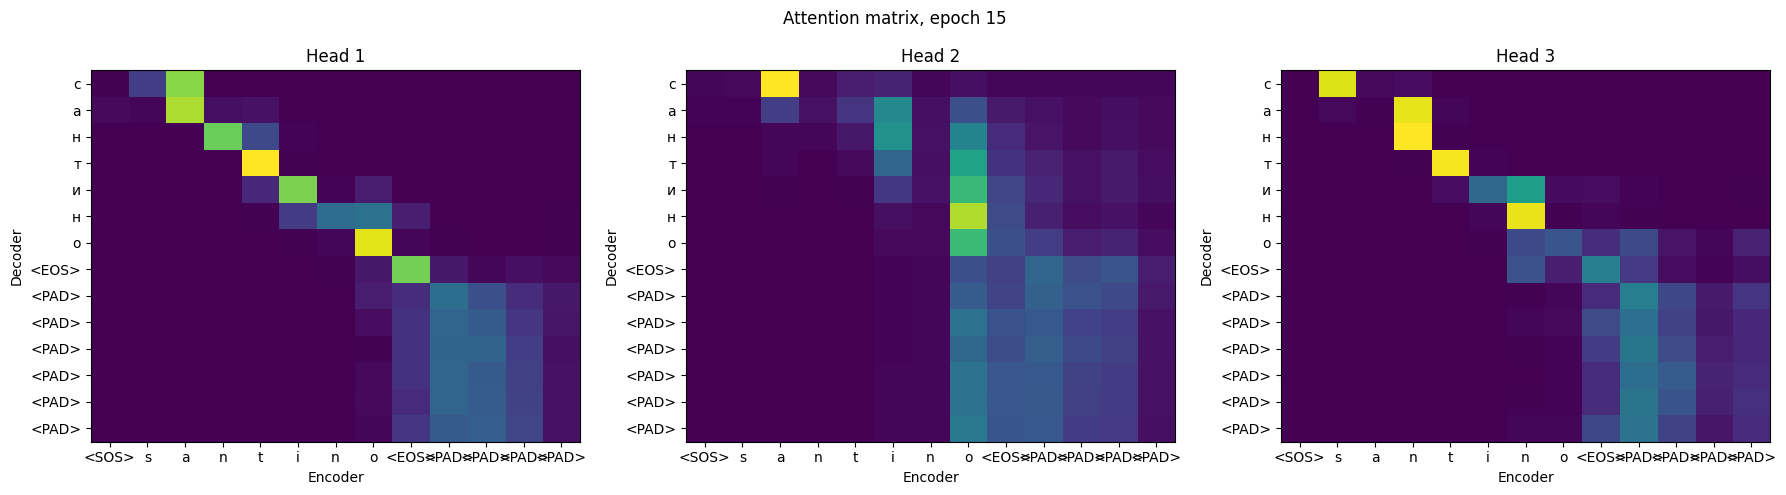

epoch 16/50, train: 0.2237, valid: 0.2963
epoch 17/50, train: 0.2127, valid: 0.3010
epoch 18/50, train: 0.2039, valid: 0.2919
epoch 19/50, train: 0.1979, valid: 0.2822
epoch 20/50, train: 0.1838, valid: 0.2832


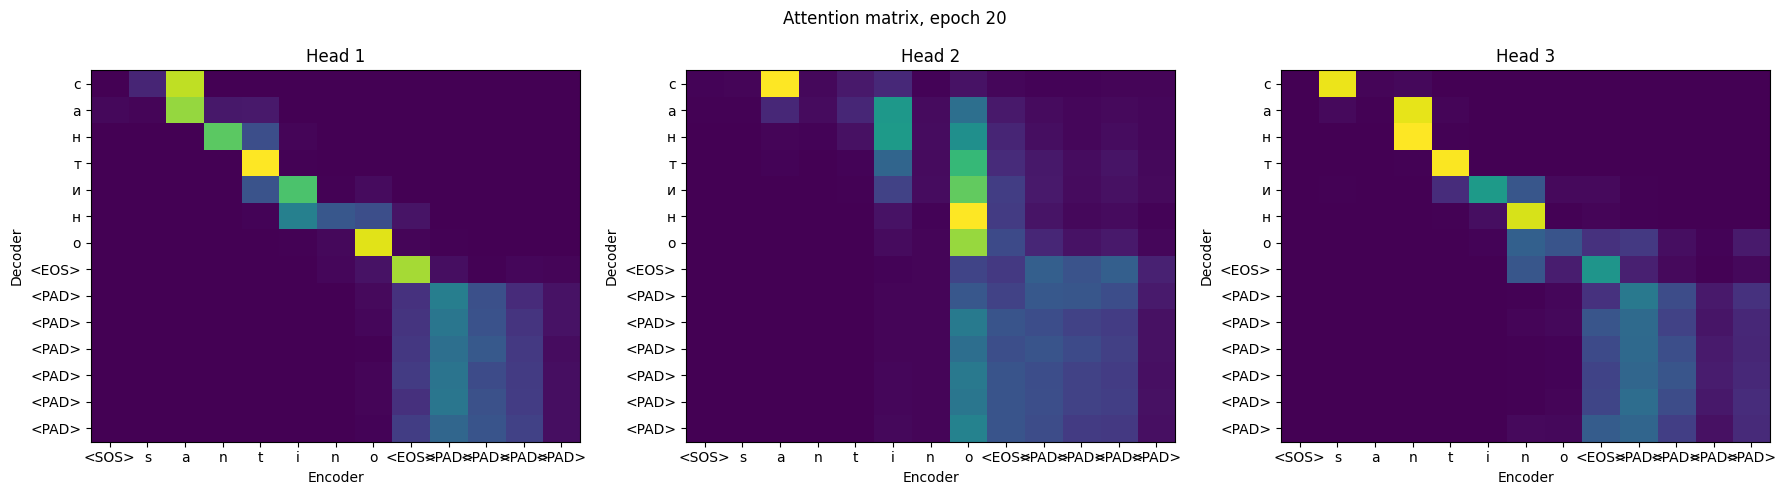

epoch 21/50, train: 0.1746, valid: 0.2856
epoch 22/50, train: 0.1664, valid: 0.2820
epoch 23/50, train: 0.1602, valid: 0.2847
epoch 24/50, train: 0.1502, valid: 0.2848
epoch 25/50, train: 0.1446, valid: 0.2859


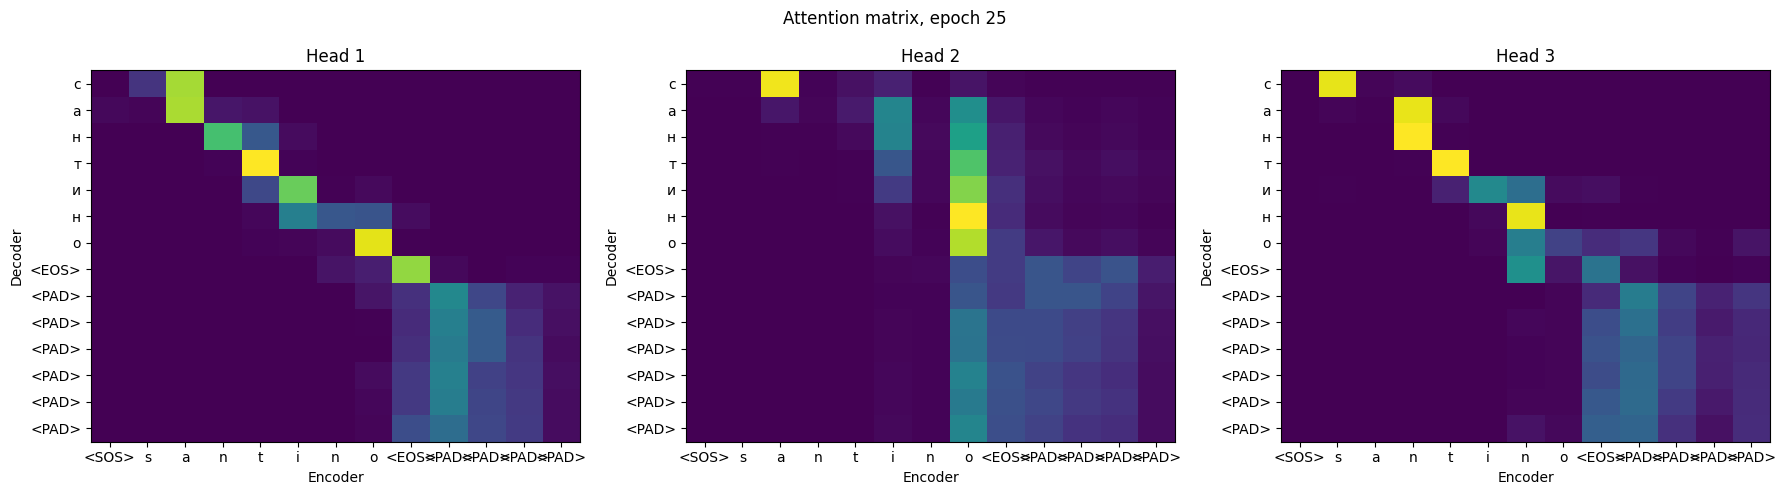

epoch 26/50, train: 0.1397, valid: 0.2867
epoch 27/50, train: 0.1335, valid: 0.2914


In [255]:
train_losses_head, valid_losses_head, best_state_head = train_multihead_attention(
    rnn_head_attention,
    train_translation_loader,
    valid_translation_loader,
    sample_x,
    sample_y,
    epochs=50,
    lr=3e-4,
    stop=5,
    print_every=5
)

## One of the heads should be almost diagonal with a shift of 1 block. Explain why there is this shift

потому что мы обучались на некст леттер предикшн, то есть декодер смотрит на свой предыдущий символ и контекстный вектор с энкодера подсчитанный через attention, и только потом через комбинацию и линейный слой выдает логиты и предсказание следующего символа, за счет некст леттер предикшн и образуется сдвиг

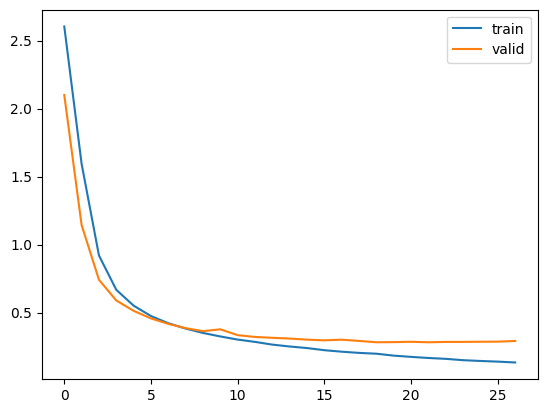

In [293]:
plt.figure()

plt.plot(train_losses_head, label='train')
plt.plot(valid_losses_head, label='valid')

plt.legend()
plt.show()

In [262]:
test_perplexity_head = evaluate_translation_perplexity(rnn_head_attention, test_translation_loader)

print(test_perplexity_head)

(0.32284848981023184, np.float64(1.3810560909830998))


In [265]:
def translate_name_attention(model, name, max_len=13, n_heads=3):
    model.eval()

    tokens = encode_tokens(pad_name(name), eng_char2id)
    tokens_t = torch.tensor([tokens], dtype=torch.long)

    with torch.no_grad():
        _, encoder_outputs, hidden = model.encoder(tokens_t)
        curr_id = torch.tensor([[ru_char2id['<SOS>']]], dtype=torch.long)
        generated = []

        encoded_contexts = [model.encoder_context[h](encoder_outputs) for h in range(n_heads)]

        for _ in range(max_len):
            embedded = model.decoder.embedding(curr_id)
            decoder_input = embedded[:, 0, :] 

            head_contexts = []
            for h in range(n_heads):
                decoder_hidden_last = hidden[-1] 
                decoder_context = model.decoder_context[h](decoder_hidden_last).unsqueeze(1)                      

                attention = model.context_attention(encoded_contexts[h] + decoder_context)
                score = model.attention_score[h](attention).squeeze(-1)
                weights = torch.softmax(score, dim=-1)
                ctx = torch.sum(weights.unsqueeze(-1) * encoder_outputs, dim=1)
                head_contexts.append(ctx)

            context_vector = torch.cat(head_contexts, dim=-1) 
        
            decoder_input = torch.cat([decoder_input, context_vector], dim=-1)

            decoder_output, hidden = model.decoder.gru(decoder_input.unsqueeze(1), hidden)
            logits = model.decoder.output_layer(decoder_output)
            next_id = torch.argmax(logits[:, -1, :], dim=-1).item()

            if next_id == ru_char2id['<EOS>']:
                break
            if next_id != ru_char2id['<PAD>']:
                generated.append(next_id)

            curr_id = torch.tensor([[next_id]], dtype=torch.long)

    return "".join(ru_id2char[i] for i in generated)

In [266]:
def print_translations_heads(translator, idxs):
    for idx in idxs[:5]:
        original = df.loc[idx, 'name']
        target = df.loc[idx, 'translated']
        prediction = translate_name_attention(translator, original)

        print(f"{original} - {prediction}, target: {target}")

In [267]:
print('train:\n')
print_translations_heads(rnn_head_attention, train_idx)

print('\nvalid:\n')
print_translations_heads(rnn_head_attention, valid_idx)

train:

Elvis - элви, target: Элвис
Khloe - кло, target: Хлоя
Alpha - алья, target: Альфа
Tanesha - теша, target: Танеша
Tennie - тен, target: Тенни

valid:

Santino - стино, target: Сантино
Terrie - тери, target: Терри
Jennings - днинг, target: Дженнингс
Ashlie - эшли, target: Эшли
Clint - клтт, target: Клинт


# submission

In [270]:
import pickle   

rnn_head_attention.load_state_dict(best_state_head)
rnn_head_attention.eval()

with open("multihead_attention_translation.pkl", "wb") as f:
    pickle.dump(
        {
            "model": rnn_head_attention,
            "eng_char2id": eng_char2id,
            "eng_id2char": eng_id2char,
            "ru_char2id": ru_char2id,
            "ru_id2char": ru_id2char,
            "max_len": max_len,
        },
        f
    )

In [276]:
idx = test_idx[0]
name = df.loc[idx, 'name']

prediction = translate_name_attention(rnn_head_attention, name)

print("name:", name)
print("prediction:", prediction)
print("target:", df.loc[idx, 'translated'])

name: Gail
prediction: гел
target: Гейл


In [281]:
predictions = []
for idx in test_idx:
    name = df.loc[idx, 'name']
    prediction = translate_name_attention(rnn_head_attention, name)
    predictions.append(prediction)

test_predictions = pd.DataFrame({
    'name': df.loc[test_idx, 'name'].values,
    'translation': predictions,
    'target': df.loc[test_idx, 'translated'].values
})

test_predictions.to_csv(
    'test_predictions.csv',
    index=False
)

# Bonus part

In [286]:
class TransformerPositionalEncoder(nn.Module):
    def __init__(self, d_model, max_len=13):
        super().__init__()
        self.d_model = d_model
        self.max_len = max_len
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0)/d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [287]:
class TransformerTranslator(nn.Module):
    def __init__(self, src_vocab_size, trg_vocab_size, d_model=128, n_heads=4, n_encoder=2, n_decoder=2, dim_feedforward=256, dropout=0.1, max_len=13, src_pad_id=None, trg_pad_id=None):
        super().__init__()
        self.src_pad_id = src_pad_id
        self.trg_pad_id = trg_pad_id
        self.encoder_embedding = nn.Embedding(src_vocab_size, d_model)
        self.decoder_embedding = nn.Embedding(trg_vocab_size, d_model)
        self.positional_encoder = TransformerPositionalEncoder(d_model, max_len)
        self.transformer = nn.Transformer(d_model=d_model, nhead=n_heads, num_encoder_layers=n_encoder, num_decoder_layers=n_decoder, dim_feedforward=dim_feedforward, dropout=dropout, batch_first=True)
        self.output_layer = nn.Linear(d_model, trg_vocab_size)

    def forward(self, src, trg):
        src_mask = src == self.src_pad_id
        trg_pad_mask = trg == self.trg_pad_id
        trg_mask = nn.Transformer.generate_square_subsequent_mask(trg.size(1))
        src_emb = self.positional_encoder(self.encoder_embedding(src))
        trg_emb = self.positional_encoder(self.decoder_embedding(trg))
        logits = self.transformer(src_emb, trg_emb, tgt_mask=trg_mask, src_key_padding_mask=src_mask, tgt_key_padding_mask=trg_pad_mask, memory_key_padding_mask=src_mask)
        return self.output_layer(logits)

In [ ]:
transformer = TransformerTranslator(src_vocab_size=len(eng_char2id), 
                    trg_vocab_size=len(ru_char2id), d_model=128, n_heads=4, 
                    n_encoder=2, n_decoder=2, dim_feedforward=256, dropout=0.1, 
                    max_len=max_len, src_pad_id=eng_char2id['<PAD>'], trg_pad_id=ru_char2id['<PAD>'])

In [289]:
def train_transformer(model, train_loader, valid_loader, epochs=50, lr=3e-4, stop=5):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(ignore_index=ru_char2id['<PAD>'])
    best_val_loss = float('inf')
    train_losses = []
    valid_losses = []
    best_state = None
    epochs_without_upgrade = 0
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for X_batch, y_batch in train_loader:
            decoder_input = y_batch[:, :-1]
            targets = y_batch[:, 1:]

            logits = model(X_batch, decoder_input)
            loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

        avg_train_loss = total_loss / len(train_loader.dataset)
        train_losses.append(avg_train_loss)

        model.eval()
        total_valid_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in valid_loader:
                decoder_input = y_batch[:, :-1]
                targets = y_batch[:, 1:]
                logits = model(X_batch, decoder_input)

                loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
                total_valid_loss += loss.item() * X_batch.size(0)

        avg_valid_loss = total_valid_loss / len(valid_loader.dataset)
        valid_losses.append(avg_valid_loss)
        print(f"epoch {epoch+1}/{epochs}, train loss: {avg_train_loss:.4f}, valid loss: {avg_valid_loss:.4f}")

        if best_val_loss > avg_valid_loss:
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_val_loss = avg_valid_loss
            epochs_without_upgrade = 0
        else:
            epochs_without_upgrade += 1

        if epochs_without_upgrade >= stop:
            break

    model.load_state_dict(best_state)

    return train_losses, valid_losses, best_state

In [290]:
transformer_train_losses, transformer_valid_losses, best_transformer_state = train_transformer(transformer, 
                                                        train_translation_loader, valid_translation_loader)

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\nn\modules\activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\nn\modules\transformer.py:529: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


epoch 1/50, train loss: 1.8465, valid loss: 0.7147
epoch 2/50, train loss: 0.7142, valid loss: 0.4373
epoch 3/50, train loss: 0.5186, valid loss: 0.3527
epoch 4/50, train loss: 0.4466, valid loss: 0.3038
epoch 5/50, train loss: 0.4035, valid loss: 0.2851
epoch 6/50, train loss: 0.3748, valid loss: 0.2760
epoch 7/50, train loss: 0.3495, valid loss: 0.2629
epoch 8/50, train loss: 0.3299, valid loss: 0.2519
epoch 9/50, train loss: 0.3164, valid loss: 0.2498
epoch 10/50, train loss: 0.3026, valid loss: 0.2464
epoch 11/50, train loss: 0.2916, valid loss: 0.2407
epoch 12/50, train loss: 0.2785, valid loss: 0.2298
epoch 13/50, train loss: 0.2680, valid loss: 0.2342
epoch 14/50, train loss: 0.2650, valid loss: 0.2350
epoch 15/50, train loss: 0.2503, valid loss: 0.2263
epoch 16/50, train loss: 0.2451, valid loss: 0.2294
epoch 17/50, train loss: 0.2402, valid loss: 0.2278
epoch 18/50, train loss: 0.2320, valid loss: 0.2119
epoch 19/50, train loss: 0.2265, valid loss: 0.2204
epoch 20/50, train lo

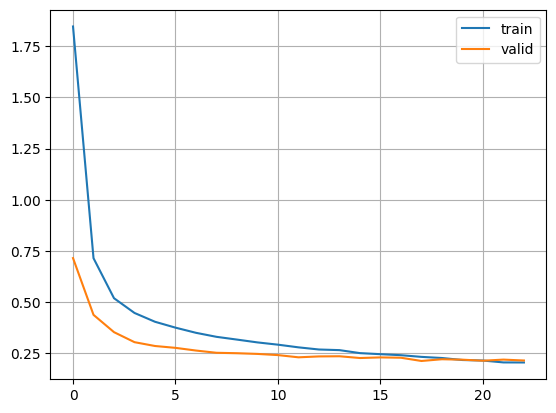

In [291]:
plt.figure()
plt.plot(transformer_train_losses, label='train')
plt.plot(transformer_valid_losses, label='valid')

plt.grid()
plt.legend()
plt.show()

In [295]:
def transformer_translate(model, x, max_len=13):
    model.eval()
    generated = torch.tensor([[ru_char2id['<SOS>']]], dtype=torch.long)

    with torch.no_grad():
        for i in range(max_len):
            logits = model(x, generated)
            next_id = torch.argmax(logits[:, -1, :], dim=-1).item()
            if next_id == ru_char2id['<EOS>'] or next_id == ru_char2id['<PAD>']:
                break
            generated = torch.cat([generated, torch.tensor([[next_id]], dtype=torch.long)], dim=1)

    return ''.join(ru_id2char[int(j)] for j in generated[0, 1:])

In [299]:
for idx in test_idx[:10]:
    x = torch.tensor([df.loc[idx, 'name_encoded']], dtype=torch.long)
    prediction = transformer_translate(transformer, x)
    print(f"{df.loc[idx, 'name']} {prediction}, target {df.loc[idx, 'translated']}")

Kirsten кирстен, target Кирстен
Daron дарон, target Даррон
Malissie малисси, target Малисси
Nealy нили, target Нили
Gaven гавен, target Гавен
Richard ричард, target Ричард
Carissa карисса, target Карисса
Corinne коринн, target Коринн
Fleda фледа, target Фледа
Conley конли, target Конли


In [312]:
from collections import Counter

def get_ngrams(text, n):
    return [text[i:i+n] for i in range(len(text) - n + 1)]

def ngram_vector(text, n, vocab):
    counts = Counter(get_ngrams(text, n))
    return np.array([counts[i] for i in vocab])

In [315]:
texts = df['translated'].str.lower().tolist()
vocab = sorted(set(g for text in texts for g in get_ngrams(text, 2)))
vector = ngram_vector("дик", 2, vocab)
vector.shape

(550,)

In [324]:
def clipped_ngram_matches(candidate, reference, n):
    candidate_counts = Counter(get_ngrams(candidate, n))
    reference_counts = Counter(get_ngrams(reference, n))
    return sum(min(counts, reference_counts.get(ngram, 0)) for ngram, counts in candidate_counts.items())

def modified_precision(candidate, reference, n):
    candidate_ngrams = get_ngrams(candidate, n)
    if len(candidate_ngrams) == 0:
        return 0.0
    return clipped_ngram_matches(candidate, reference, n) / len(candidate_ngrams)

def penalty(candidate, refeernce):
    c, r = len(candidate), len(reference)
    if c == 0:
        return 0.0
    return 1.0 if c > r else np.exp(1-r/c)

def bleu(candidate, reference, max_n=4, eps=1e-10):
    precision = [max(modified_precision(candidate, reference, n), eps) for n in range(1, max_n+1)]
    return penalty(candidate, reference) * np.exp(np.mean(np.log(precision)))

In [323]:
transformer_predictions = []
transformer_references = []

for idx in test_idx:
    x = torch.tensor([df.loc[idx, 'name_encoded']], dtype=torch.long)
    prediction = transformer_translate(transformer, x).lower()
    reference = df.loc[idx, 'translated'].lower()
    transformer_predictions.append(prediction)
    transformer_references.append(reference)

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\nn\modules\activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


In [326]:
bleu_score = [bleu(cand, ref) for cand, ref in zip(transformer_predictions, transformer_references)]
mean_bleu = np.mean(bleu_score)
print(mean_bleu)

0.7863171733160841


In [329]:
for pred, ref, idx in zip(transformer_predictions[:10], transformer_references[:10], test_idx[:10]):
    print(f"{df.loc[idx, 'name']} {pred}, target {ref}, bleu: {bleu(pred, ref)}")

Kirsten кирстен, target кирстен, bleu: 1.0
Daron дарон, target даррон, bleu: 0.0028574404296987997
Malissie малисси, target малисси, bleu: 1.0
Nealy нили, target нили, bleu: 1.0
Gaven гавен, target гавен, bleu: 1.0
Richard ричард, target ричард, bleu: 1.0
Carissa карисса, target карисса, bleu: 1.0
Corinne коринн, target коринн, bleu: 1.0
Fleda фледа, target фледа, bleu: 1.0
Conley конли, target конли, bleu: 1.0


забавный момент что всего за одну ошибку bleu дает меньше 1 процента точности по всему слову, проблема в том что при нулевой нграмме мы получаем значение eps 1e-10, за счет чего через np.mean() все усредняется к нулю. хотя оно и понятно ибо метрика создана для текстов а не разовых слов где нграмма охватывает все слово